# Search-03d — Weighted A\* : recherche à sous-optimalité bornée

**Navigation** : [<< Search-03c — LDS](Search-03c-LimitedDiscrepancySearch.ipynb) | [Index](README.md) | [Search-03e — optimalité de A\* >>](Search-03e-AStar-Optimality.ipynb) | [jumeau Rust](Search-03d-WeightedAstar-Rust.ipynb)

> **Partie 3 — Recherche avancée.** Ce notebook complète le **triptyque** de la
> Partie 3 sur la question « l'heuristique ne suffit pas à résoudre à l'optimum ».
> Là où [Search-03b](Search-03b-PatternDatabases.ipynb) *renforce* l'heuristique (PDB)
> et [Search-03c](Search-03c-LimitedDiscrepancySearch.ipynb) *borne les écarts* (LDS) —
> toutes deux **en gardant l'optimalité** — voici la troisième réponse : **renoncer
> (partiellement) à l'optimalité pour gagner en vitesse**, mais de façon *contrôlée*.

## 1. L'idée : payer l'optimalité pour acheter de la vitesse

[Search-3 (Informed)](../Part1-Foundations/Search-03-Informed.ipynb) a posé le
compromis fondateur : **A\*** (heuristique consistante pour la variante sans ré-ouverture) est optimal mais peut explorer beaucoup
de nœuds ; **Greedy** (sans `g`) est rapide mais peut renvoyer une solution
carrément mauvaise. Entre l'optimalité chère et la gloutonnerie aveugle, existe-t-il
un **juste milieu garanti** ?

**Weighted A\*** (Pohl, 1970) répond oui. On garde la structure d'A\*, mais on
**inflate l'heuristique** par un facteur $W \geq 1$ :

$$f(n) = g(n) + W \cdot h(n)$$

- $W = 1$ : on retrouve A\* (optimal, mais explore beaucoup).
- $W \to \infty$ : on tend vers Greedy (rapide, mais sous-optimal sans garantie).
- $1 < W < \infty$ : **Weighted A\***, qui explore bien moins de nœuds qu'A\* tout en
  garantissant une solution de coût **au pire $W$ fois l'optimal** (sous-optimalité
  bornée par $W$).

C'est le compromis « bon citizen » : on sait exactement jusqu'où on dérive de
l'optimum, et on l'échange contre un gain de nœuds qui peut être de plusieurs ordres
de grandeur.

## 2. Le banc d'essai : cheminement sur un terrain pondéré

Pour mettre Weighted A\* en valeur, il faut un problème où **A\* explore beaucoup**
(où l'optimalité coûte de nombreux nœuds) et où le compromis vitesse/qualité est net :
un terrain pondéré (routes rapides, herbe lente, marécages quasi-impraticables, murs). Sur un graphe à coût uniforme, A\*
dégenère en BFS et Weighted A\* n'apporte rien (cf la leçon « problème dégénéré ») —
il faut des **coûts contrastés** pour que l'heuristique et l'inflation discriminent.


In [1]:
import heapq
import random
from itertools import product

# --- Terrain pondere : chaque case a un cout de traversee ---
# 1 = route (rapide), 3 = herbe, 8 = marécage, '#' = mur infranchissable.
# Coûts CONTRASTES -> A* explore beaucoup, Greedy se trompe (non-dégenéré).
TERRAIN_COST = {".": 1, "g": 3, "s": 8, "#": None}   # s = swamp, g = grass

def make_grid(rows, cols, seed=42):
    rng = random.Random(seed)
    grid = {}
    for r, c in product(range(rows), range(cols)):
        x = rng.random()
        if x < 0.15:
            grid[(r, c)] = "#"          # mur (15%)
        elif x < 0.45:
            grid[(r, c)] = "g"          # herbe (30%)
        elif x < 0.60:
            grid[(r, c)] = "s"          # marécage (15%)
        else:
            grid[(r, c)] = "."          # route (40%)
    # garantir départ + arrivée franchissables
    start, goal = (0, 0), (rows - 1, cols - 1)
    grid[start], grid[goal] = ".", "."
    return grid

ROWS, COLS = 25, 25
grid = make_grid(ROWS, COLS, seed=42)
start, goal = (0, 0), (ROWS - 1, COLS - 1)

def step_cost(grid, cur, nxt):
    t = grid.get(nxt, "#")
    return TERRAIN_COST.get(t)          # None si mur

def neighbors(grid, s):
    r, c = s
    out = []
    for dr, dc in ((-1, 0), (1, 0), (0, -1), (0, 1)):
        n = (r + dr, c + dc)
        if 0 <= n[0] < ROWS and 0 <= n[1] < COLS and step_cost(grid, s, n) is not None:
            out.append(n)
    return out

# Heuristique : Manhattan (admissible : min cost = 1, distance >= Manhattan*1).
def manhattan(a, b):
    return abs(a[0] - b[0]) + abs(a[1] - b[1])

n_walls = sum(1 for v in grid.values() if v == "#")
print(f"Grille {ROWS}x{COLS} : {n_walls} murs ({100*n_walls/(ROWS*COLS):.0f}%), "
      f"départ {start}, but {goal}.")
print("Coûts contrastés (route=1, herbe=3, marécage=8) -> A* va explorer, "
      "Greedy va se tromper : terrain non-dégénéré.")


Grille 25x25 : 90 murs (14%), départ (0, 0), but (24, 24).
Coûts contrastés (route=1, herbe=3, marécage=8) -> A* va explorer, Greedy va se tromper : terrain non-dégénéré.


## 3. A\*, Greedy, et Weighted A\* : un seul algorithme paramétré

Les algorithmes se ramènent à **un même best-first search** sur $f(n) = g(n) + W \cdot h(n)$ :
le **poids $W$ de l'heuristique** est le seul paramètre. $W=1$ → A\* (optimal) ; $W>1$ →
Weighted A\* (sous-optimalité **bornée par $W$**) ; $W \to \infty$ → Greedy (l'heuristique
domine, $g$ devient négligeable). À noter : $W=0$ donne $f=g$, c'est-à-dire **Dijkstra/UCS**
(optimal mais aveugle à l'heuristique) — pas Greedy ; le vrai Greedy ($f=h$, $g$ ignoré) est
traité à part comme pôle non borné. On instrumente le **nombre de nœuds développés** (coût
de la recherche) et le **coût de la solution trouvée** (sa qualité).


In [2]:
def best_first(grid, start, goal, W, h=manhattan):
    # f(n) = g(n) + W*h(n). W=1 -> A* ; W>1 -> Weighted A* (borne W).
    g = {start: 0}
    parent = {start: None}
    open_h = [(W * h(start, goal), start)]      # file de priorité sur f
    developed = 0
    while open_h:
        _, cur = heapq.heappop(open_h)
        developed += 1
        if cur == goal:
            # reconstruire le chemin
            path = []
            while cur is not None:
                path.append(cur)
                cur = parent[cur]
            return list(reversed(path)), g[goal], developed
        for nxt in neighbors(grid, cur):
            nc = g[cur] + step_cost(grid, cur, nxt)
            if nxt not in g or nc < g[nxt]:
                g[nxt] = nc
                parent[nxt] = cur
                heapq.heappush(open_h, (nc + W * h(nxt, goal), nxt))
    return None, float("inf"), developed     # pas de chemin

# Vrai Greedy best-first (f = h uniquement, g ignore) : le pole NON BORNE.
# On garde g pour reconstruire le chemin et mesurer son cout reel.
def true_greedy(grid, start, goal, h=manhattan):
    g = {start: 0}; parent = {start: None}
    open_h = [(h(start, goal), start)]
    developed = 0; seen = set()
    while open_h:
        _, cur = heapq.heappop(open_h); developed += 1
        if cur in seen: continue
        seen.add(cur)
        if cur == goal:
            path = []
            while cur is not None: path.append(cur); cur = parent[cur]
            return list(reversed(path)), g[goal], developed
        for nxt in neighbors(grid, cur):
            nc = g[cur] + step_cost(grid, cur, nxt)
            if nxt not in g or nc < g[nxt]:
                g[nxt] = nc; parent[nxt] = cur
                heapq.heappush(open_h, (h(nxt, goal), nxt))   # f = h seulement
    return None, float("inf"), developed

# Repères : A* (W=1) = référence optimale ; Greedy (f=h) = pôle rapide non borné.
astar_path, astar_cost, astar_nodes = best_first(grid, start, goal, W=1)
greedy_path, greedy_cost, greedy_nodes = true_greedy(grid, start, goal)
print(f"A*     (W=1, optimal)   : coût = {astar_cost:3d} | nœuds développés = {astar_nodes}")
print(f"Greedy (f=h, non borné) : coût = {greedy_cost:3d} | nœuds développés = {greedy_nodes}"
      f"  (ratio = {greedy_cost/astar_cost:.2f}× optimal, AUCUNE borne)")
optimal = astar_cost   # A* admissible -> référence d'optimalité
print(f"\nRéférence d'optimalité (A* admissible) : {optimal}.")


A*     (W=1, optimal)   : coût =  78 | nœuds développés = 472
Greedy (f=h, non borné) : coût = 143 | nœuds développés = 60  (ratio = 1.83× optimal, AUCUNE borne)

Référence d'optimalité (A* admissible) : 78.


## 4. Le balayage de $W$ : la frontière coût/nœuds

Faisons varier $W$ de 1 (A\* optimal) à de grandes valeurs (proche Greedy). À chaque
$W$, on mesure **le coût de la solution** et **le nombre de nœuds développés**. La
promesse de Weighted A\* est double, et on la vérifie honnêtement :

1. **Vitesse** — à mesure que $W$ croît, le nombre de nœuds **chute**.
2. **Garantie** — le coût de la solution reste **$\leq W \cdot \text{optimal}$** (Pohl 1970).


In [3]:
# Balayage de W >= 1 (le régime Weighted A*) : A* (W=1) -> de plus en plus "confiant".
# Greedy (f=h, pôle non borné) a déjà été mesuré ci-dessus ; ici on explore la BORNE W.
weights = [1.0, 1.5, 2.0, 3.0, 5.0, 8.0, 12.0]
print(f"{'W':>5} | {'coût':>5} | {'ratio/opt':>9} | {'borne W':>7} | {'nœuds':>6} | {'% A*':>6} | garantie?")
print("-" * 66)
rows = []
for W in weights:
    path, cost, nodes = best_first(grid, start, goal, W=W)
    ratio = cost / optimal
    pct = 100.0 * nodes / astar_nodes
    garantit = "OUI" if cost <= W * optimal + 1e-9 else "NON"
    print(f"{W:5.1f} | {cost:5d} | {ratio:9.3f} | {W:7.2f} | {nodes:6d} | {pct:5.1f}% | {garantit}")
    rows.append((W, cost, ratio, nodes, pct))


    W |  coût | ratio/opt | borne W |  nœuds |   % A* | garantie?
------------------------------------------------------------------
  1.0 |    78 |     1.000 |    1.00 |    472 | 100.0% | OUI
  1.5 |    78 |     1.000 |    1.50 |    162 |  34.3% | OUI
  2.0 |    78 |     1.000 |    2.00 |     80 |  16.9% | OUI
  3.0 |    89 |     1.141 |    3.00 |     57 |  12.1% | OUI
  5.0 |    89 |     1.141 |    5.00 |     55 |  11.7% | OUI
  8.0 |   104 |     1.333 |    8.00 |     52 |  11.0% | OUI
 12.0 |   104 |     1.333 |   12.00 |     52 |  11.0% | OUI


In [4]:
# Visualisation ASCII : le chemin trouvé par A* (W=1) vs Weighted A* (W=3) vs Greedy (W=0).
def render(grid, path):
    sym = {".": ".", "g": ",", "s": "~", "#": "#"}
    cells_map = {s: sym[t] for s, t in grid.items()}
    for s in path:
        cells_map[s] = "@"        # le chemin
    cells_map[start] = "S"; cells_map[goal] = "G"
    lines = []
    for r in range(ROWS):
        lines.append("".join(cells_map[(r, c)] for c in range(COLS)))
    return "\n".join(lines)

wa3_path, _, _ = best_first(grid, start, goal, W=3.0)
print("Légende : S départ · G but · @ chemin · . route · , herbe · ~ marécage · # mur\n")
print("=== A* (W=1, optimal) ===")
print(render(grid, astar_path))
print("\n=== Weighted A* (W=3) ===")
print(render(grid, wa3_path))


Légende : S départ · G but · @ chemin · . route · , herbe · ~ marécage · # mur

=== A* (W=1, optimal) ===
S#,,...#,#,~#,.~,~.#..,,.
@##....~.,~...~.#,,#,#,.,
@@,...,.,,..~...,#,,,..,.
,@~,,~,~.,,.~###..,#,.~..
#@@~,.#,~..,~,..,..,.~.~#
,#@..,#..#~#..#~~,.,,~.,,
..@~#,,~,,#.,..#,.,#.~~..
,#@,~...#,,.,,,,,,.,.~#..
..@,~,,#,.,.~,..~.,,.~~.#
~~@@@#,~.,#.,~.,~~.,.,,.,
,.#~@@#,,...,,.....#.,..#
##~,.@@@,~..#,,#..,.~,##.
.~.~##,@@@@,,#..,.,.....#
.,....,.#.@@@~,.,#,,..,.,
.~.#.,.,#,.,@~,~,.#.~...,
#.,,..,,,,,#@@@@@,~#,,~.~
,,~..,#~.,...,,#@~.#,.,.~
,.#..#,,.~#,.~..@~@@@.~.~
..~,,..~.,#,,,~#@@@#@~,,,
.~...,#,...,.~.,,,#,@,,~#
.#,~#.#~#,,,.,..,##~@@@@.
..,#,#.~,..,..#..##,..,@#
..#...#..,,,~,..#....,.@@
.~~,.,..#.,~.,#.,,.,..,#@
#.~...~.#,.,~~~,.,.,,#,#G

=== Weighted A* (W=3) ===
S#,,...#,#,~#,.~,~.#..,,.
@##....~.,~...~.#,,#,#,.,
@@,...,.,,..~...,#,,,..,.
,@~,,~,~.,,.~###..,#,.~..
#@@~,.#,~..,~,..,..,.~.~#
,#@@@@#..#~#..#~~,.,,~.,,
..,~#@,~,,#.,..#,.,#.~~..
,#,,~@@.#,,.,,,,,,.,.~#..
...,~,@#,

### Lecture du résultat

Les repères et le balayage encadrent le **compromis structurel** de Weighted A\* par ses
deux pôles, puis l'interpolation bornée entre les deux :

- **Greedy (f=h) — pôle rapide, NON borné.** Seulement **60 nœuds**, mais un coût de
  **143 (1,83× l'optimal)**. Greedy « fonce » vers le but : parfois il tombe juste, parfois
  (comme ici) très mal — on n'a **aucune garantie** sur sa dérive, qui peut être arbitraire.
- **A\* (W=1) — pôle optimal, cher.** Coût **78 (optimal garanti)**, mais **472 nœuds** :
  c'est le prix de l'optimalité stricte, A\* explore largement autour du chemin pour prouver
  qu'aucun meilleur n'existe.
- **Weighted A\* (1 < W) — l'interpolation bornée.** C'est tout l'intérêt : à $W=2$, on
  retrouve **le coût optimal (78)** en ne développant que **80 nœuds (17 % d'A\*)** — un gain
  quasi gratuit. À $W=3$, **57 nœuds (12 %)** pour un coût **89 (1,14× l'optimal)**. La
  colonne « garantie » confirme partout : $\text{coût} \leq W \cdot \text{optimal}$.

La **frontière de Pareto** se lit ainsi : choisir $W$, c'est choisir un point sur la courbe
coût/nœuds. Un $W$ modeste ($2$ à $3$) capture l'essentiel du gain de vitesse pour une dérive
qualité négligeable — tandis que Greedy, lui, abandonne toute borne sur la sienne.

La carte ASCII montre l'effet visuel : A\* ($W=1$) contourne méthodiquement les zones coûteuses
(chemin optimal), tandis que Weighted A\* ($W=3$) « coupe » à travers des cases un peu plus
chères pour aller plus droit — un chemin légèrement plus cher (89 vs 78), trouvé en développant
**8 fois moins** de nœuds (57 vs 472).


## 5. Pourquoi ça marche : la garantie de sous-optimalité bornée

La garantie $\text{coût} \leq W \cdot \text{optimal}$ repose sur une idée simple. En
gonflant l'heuristique par $W$, on rend la recherche **plus confiante** dans l'estimation
$h$ : elle « fonce » vers le but en s'autorisant à développer moins de nœuds latéraux.
Le prix de cette confiance est qu'on peut manquer le chemin optimal — mais le facteur
d'inflation $W$ **borne exactement** de combien on peut dévier.

Formellement (Pohl 1970) : si $h$ est **admissible** ($h \leq h^*$, vrai coût), alors la
solution de Weighted A\* avec facteur $W$ a un coût au plus $W \cdot C^*$, où $C^*$ est le
coût optimal. La preuve suit la même structure que l'optimalité d'A\* : au moment où le
but est développé, son $f$-valeur est bornée par $W \cdot C^*$ via les nœuds sur le chemin
optimal, dont l'$f$ gonflé reste sous ce seuil.

Conséquences pratiques :
- **Choisir $W$, c'est choisir le budget d'erreur acceptable.** Si on tolère une solution
  10 % trop chère, $W = 1{,}1$ suffit — souvent avec un gain de nœuds déjà notable.
- **L'heuristique doit rester admissible.** Gonfler une heuristique *déjà inadmissible*
  n'offre plus de garantie — Weighted A\* suppose un $h$ honnête qu'on choisit de
  sur-pondérer.
- **Anytime** — on peut démarrer avec un grand $W$ (solution rapide, grossière) puis le
  réduire progressivement en réutilisant la recherche, pour raffiner vers l'optimal
  (Anytime Repairing A\*, Likhachev 2003 — exercice 3).


## 6. Ponts avec le reste de la série

| Direction | Lien | Relation |
|-----------|------|----------|
| ↔ Search-03b | [Search-03b — Pattern Databases](Search-03b-PatternDatabases.ipynb) | Autre réponse à « l'optimum est dur » : *renforcer* l'heuristique (rester optimal) vs ici *relâcher* l'optimalité |
| ↔ Search-03c | [Search-03c — Limited Discrepancy Search](Search-03c-LimitedDiscrepancySearch.ipynb) | LDS *borne les écarts* à l'heuristique (rester optimal) ; Weighted A\* *relâche* l'optimalité — deux axes orthogonaux |
| ← Partie 1 | [Search-3 — Informed](../Part1-Foundations/Search-03-Informed.ipynb) | A\*, admissibilité, Greedy : les deux extrémités ($W=1$ et $W=0$) que Weighted A\* interpole |
| → Partie 4 | [Métaheuristiques](../Part4-Metaheuristics/README.md) | Weighted A\* garde une *borne* sur la qualité ; les métaheuristiques l'abandonnent totalement |

**Triptyque de la Partie 3** — trois réponses à « l'heuristique ne suffit pas à résoudre à
l'optimum » : **renforcer** l'heuristique (Search-03b, PDB), **borner les écarts**
(Search-03c, LDS), **relâcher** l'optimalité (Search-03d, Weighted A\*).

**Référence fondatrice** : Pohl, I. (1970) — *Heuristic Search Viewed as Path Finding in a
Graph*, Artificial Intelligence 1(3-4). Première formalisation de Weighted A\* et de sa
garantie de sous-optimalité bornée par le facteur d'inflation $W$.


## 7. Exercices

### Exercice 1 : courbe de Pareto coût/nœuds
Tracez (ou affichez en ASCII) la **frontière de Pareto** : en abscisse le nombre de nœuds
développés, en ordonnée le ratio coût/optimal, un point par valeur de $W \in [1, 12]$.
Identifiez le « genou » (knee) — la valeur de $W$ au-delà de laquelle gagner encore en
vitesse coûte cher en qualité.
- **Indice :** le genou est typiquement autour de $W \in [2, 3]$. Justifiez pourquoi
  l'utilité marginale d'augmenter $W$ décroît (les nœuds économisés s'amenuisent, la
  dérive quality s'accumule).


Balayage : 221 valeurs de W dans [1, 12] -> 26 résultats distincts, 3 points sur la frontière de Pareto.

   plage de W | coût | ratio |  nœuds | statut
----------------------------------------------------
         1.00 |   78 | 1.000 |    472 | dominé par (72 nœuds, coût 78)
         1.05 |   78 | 1.000 |    492 | dominé par (72 nœuds, coût 78)
         1.10 |   78 | 1.000 |    469 | dominé par (72 nœuds, coût 78)
         1.15 |   78 | 1.000 |    450 | dominé par (72 nœuds, coût 78)
         1.20 |   78 | 1.000 |    425 | dominé par (72 nœuds, coût 78)
         1.25 |   78 | 1.000 |    389 | dominé par (72 nœuds, coût 78)
         1.30 |   78 | 1.000 |    344 | dominé par (72 nœuds, coût 78)
         1.35 |   78 | 1.000 |    301 | dominé par (72 nœuds, coût 78)
         1.40 |   78 | 1.000 |    257 | dominé par (72 nœuds, coût 78)
         1.45 |   78 | 1.000 |    186 | dominé par (72 nœuds, coût 78)
         1.50 |   78 | 1.000 |    162 | dominé par (72 nœuds, coût 78)
         1.55

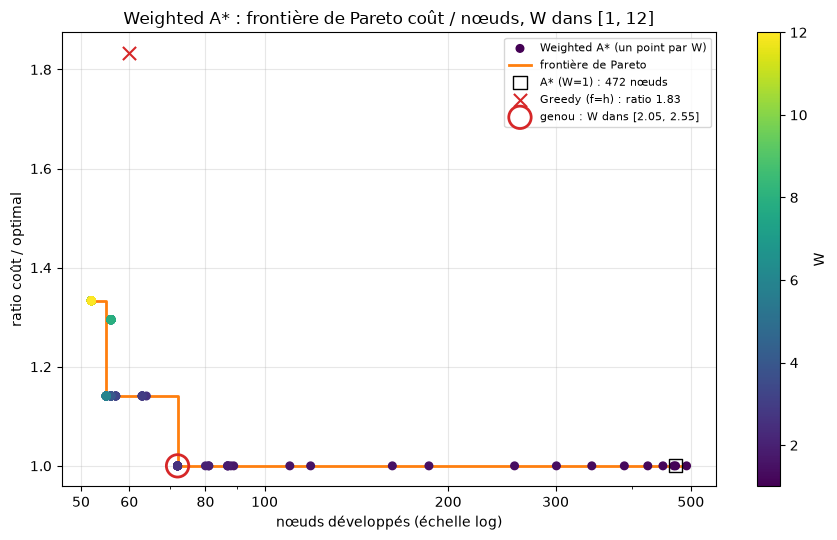

In [5]:
# Exercice 1 : frontiere de Pareto cout/noeuds de Weighted A*
import numpy as np
import matplotlib.pyplot as plt

# --- 1. Balayage fin de W sur [1, 12] (pas de 0,05) : un point par valeur de W ---
W_grid = np.round(np.arange(1.0, 12.0 + 1e-9, 0.05), 2)
sweep = []                                    # (W, cout, noeuds)
for W in W_grid:
    _, cost, nodes = best_first(grid, start, goal, W=float(W))
    sweep.append((float(W), cost, nodes))

# Des W voisins donnent souvent exactement le meme resultat : on les regroupe en plages.
plages = []                                   # [W_min, W_max, cout, noeuds]
for W, cost, nodes in sweep:
    if plages and (plages[-1][2], plages[-1][3]) == (cost, nodes):
        plages[-1][1] = W
    else:
        plages.append([W, W, cost, nodes])

# --- 2. Frontiere de Pareto : on minimise (noeuds, cout) ---
# a domine b si a n'est pire sur aucun critere et strictement meilleur sur au moins un.
def domine(a, b):
    return a[0] <= b[0] and a[1] <= b[1] and a != b

points = sorted({(nodes, cost) for _, _, cost, nodes in plages})
front = [p for p in points if not any(domine(q, p) for q in points)]   # tri par noeuds croissants

print(f"Balayage : {len(W_grid)} valeurs de W dans [1, 12] -> {len(plages)} résultats distincts, "
      f"{len(front)} points sur la frontière de Pareto.\n")
print(f"{'plage de W':>13} | {'coût':>4} | {'ratio':>5} | {'nœuds':>6} | statut")
print("-" * 52)
for w_min, w_max, cost, nodes in plages:
    plage = f"{w_min:.2f}" if w_min == w_max else f"{w_min:.2f}-{w_max:.2f}"
    if (nodes, cost) in front:
        statut = "Pareto"
    else:
        dominant = min((q for q in front if domine(q, (nodes, cost))), key=lambda q: q[0])
        statut = f"dominé par ({dominant[0]} nœuds, coût {dominant[1]})"
    print(f"{plage:>13} | {cost:4d} | {cost / optimal:5.3f} | {nodes:6d} | {statut}")

# --- 3. Le genou : le point de la frontiere le plus eloigne de la corde ---
# La corde relie les deux extremites du compromis : A* (W=1, optimal mais cher) et le point
# le plus rapide du balayage. En coordonnees normalisees (u = noeuds, v = surcout, tous deux
# ramenes dans [0, 1]), la corde est la droite u + v = 1 ; le genou est le point qui s'en
# ecarte le plus vers l'origine, c'est-a-dire le meilleur compromis des deux criteres.
n_min, n_max = front[0][0], astar_nodes
c_min, c_max = optimal, front[0][1]
def ecart_a_la_corde(p):
    u = (p[0] - n_min) / (n_max - n_min)
    v = (p[1] - c_min) / (c_max - c_min)
    return (1 - u - v) / np.sqrt(2)

genou = max(front, key=ecart_a_la_corde)
W_genou = [(w_min, w_max) for w_min, w_max, cost, nodes in plages if (nodes, cost) == genou]
print(f"\nGenou : {genou[0]} nœuds, coût {genou[1]} (ratio {genou[1] / optimal:.3f}), "
      f"obtenu pour W dans " + ", ".join(f"[{a:.2f}, {b:.2f}]" for a, b in W_genou))

# --- 4. Utilite marginale : combien coute chaque noeud economise, d'un point a l'autre ---
print("\nTaux d'échange le long de la frontière (en partant d'A*) :")
chemin = [(astar_nodes, optimal)] + front[::-1]       # noeuds decroissants
for (n1, c1), (n2, c2) in zip(chemin, chemin[1:]):
    gain = n1 - n2
    surcout = 100 * (c2 - c1) / optimal               # en points de % de l'optimal
    print(f"  {n1:4d} -> {n2:3d} nœuds : {gain:3d} nœuds économisés pour +{surcout:4.1f} pts "
          f"de surcoût, soit {surcout / gain:5.2f} pt par nœud")

# Repere : ou se place le Greedy (f=h, mesure plus haut) par rapport a la frontiere ?
dominants_greedy = [q for q in front if domine(q, (greedy_nodes, greedy_cost))]
print(f"\nRepère : Greedy ({greedy_nodes} nœuds, ratio {greedy_cost / optimal:.3f}) est dominé par "
      + ", ".join(f"({n} nœuds, ratio {c / optimal:.3f})" for n, c in dominants_greedy))

# --- 5. Trace ---
fig, ax = plt.subplots(figsize=(9, 5.5))
sc = ax.scatter([s[2] for s in sweep], [s[1] / optimal for s in sweep], c=[s[0] for s in sweep],
                cmap="viridis", s=30, zorder=3, label="Weighted A* (un point par W)")
fig.colorbar(sc, ax=ax, label="W")
# Frontiere en escalier : meilleur ratio atteignable pour un budget de noeuds donne.
fx = [n for n, _ in front] + [max(s[2] for s in sweep)]
fy = [c / optimal for _, c in front] + [1.0]
ax.step(fx, fy, where="post", color="tab:orange", lw=2, zorder=2, label="frontière de Pareto")
ax.scatter([astar_nodes], [1.0], marker="s", s=90, facecolors="none", edgecolors="black",
           zorder=4, label=f"A* (W=1) : {astar_nodes} nœuds")
ax.scatter([greedy_nodes], [greedy_cost / optimal], marker="x", s=90, color="tab:red",
           zorder=4, label=f"Greedy (f=h) : ratio {greedy_cost / optimal:.2f}")
ax.scatter([genou[0]], [genou[1] / optimal], s=260, facecolors="none", edgecolors="tab:red",
           lw=2, zorder=5, label=f"genou : W dans [{W_genou[0][0]:.2f}, {W_genou[0][1]:.2f}]")
ax.set_xscale("log")
ax.set_xticks([50, 60, 80, 100, 200, 300, 500])
ax.xaxis.set_major_formatter(plt.ScalarFormatter())
ax.xaxis.set_minor_formatter(plt.NullFormatter())
ax.set_xlabel("nœuds développés (échelle log)")
ax.set_ylabel("ratio coût / optimal")
ax.set_title("Weighted A* : frontière de Pareto coût / nœuds, W dans [1, 12]")
ax.grid(alpha=0.3)
ax.legend(loc="upper right", fontsize=8)
plt.tight_layout()
plt.show()

### Lecture du résultat

**Le genou est à $W \in [2{,}05 ; 2{,}55]$** : 72 nœuds pour un coût de 78, encore optimal. C'est le dernier point de la frontière qui ne paie rien en qualité. A\* ($W=1$) est d'ailleurs dominé par lui : même coût, mais 472 nœuds au lieu de 72. Au-delà du genou, chaque nœud économisé se paie en qualité, et de plus en plus cher.

**Pourquoi l'utilité marginale d'augmenter $W$ décroît.** Les taux d'échange le long de la frontière le chiffrent :

| Passage | Nœuds économisés | Surcoût | Prix d'un nœud économisé |
|---|---|---|---|
| A\* → genou ($W \approx 2$) | 400 | +0,0 pt | 0 |
| genou → 55 nœuds ($W \geq 4{,}05$) | 17 | +14,1 pts | 0,83 pt |
| 55 → 52 nœuds ($W \geq 8$) | 3 | +19,2 pts | 6,41 pts |

Deux effets se combinent :

- **Les nœuds économisables s'épuisent.** Entre A\* et le genou, l'inflation de $h$ ne fait qu'élaguer les nœuds latéraux qu'A\* développait pour *prouver* l'optimalité : le chemin renvoyé ne change pas, l'économie est gratuite. Ensuite, il ne reste presque plus rien à élaguer. Chaque état du chemin renvoyé est développé, et un chemin de $(0,0)$ à $(24,24)$ compte au moins 49 cases : à 52 nœuds, la recherche est au plancher.
- **La dérive s'accumule par paliers.** Le coût ne prend que quelques valeurs discrètes (78, 89, puis 104 sur la frontière) : chaque palier correspond à un chemin différent, plus cher, que la recherche accepte parce que $W \cdot h$ le fait paraître plus proche du but. Le dernier palier rapporte 3 nœuds et coûte près de 20 points.

**Ce que le balayage fin ajoute au tableau de la section 4** :

- Il trouve mieux que $W=2$ : à $W \in [2{,}05 ; 2{,}55]$, le coût reste optimal pour 72 nœuds au lieu de 80.
- Augmenter $W$ n'améliore pas toujours le compromis. $W \in [6 ; 7{,}95]$ donne un coût de 101 pour 56 nœuds, dominé par $W \in [4{,}05 ; 5{,}95]$ (coût 89, 55 nœuds). La frontière ne se lit donc pas comme « plus de $W$, plus de vitesse ».
- $W = 1{,}05$ développe 492 nœuds, plus qu'A\*. Avec $W > 1$, l'heuristique gonflée n'est plus consistante : des états sont réinsérés dans la file avec un meilleur $g$, et `best_first` compte chaque extraction de la file, doublons périmés compris.
- Greedy (60 nœuds, ratio 1,833) est dominé par deux points de la frontière. Sur cette instance, la borne de Weighted A\* ne coûte aucune vitesse par rapport au Greedy.

Ces valeurs valent pour cette grille (seed 42) : sur une autre instance, la position exacte du genou bougerait, et c'est la mesure qui la situe.

### Exercice 2 : sensibilité à l'heuristique (admissible vs inadmissible)
Refaitez le balayage de $W$ avec une heuristique **inadmissible** (par ex. Manhattan
**sans** tenir compte du coût minimal : ou $h$ sur-estimé d'un facteur 2 dès le départ).
Vérifiez que la **garantie** $\text{coût} \leq W \cdot \text{optimal}$ est alors **violée**.
- **Indice :** la garantie suppose $h$ admissible. Avec un $h$ déjà inadmissible, l'inflation
  par $W$ aggrave la triche et la borne n'a plus de raison de tenir. C'est pourquoi Weighted
  A\* part toujours d'une heuristique *honnête*.


In [6]:
# Exercice 2 a completer
# Conseil : définissez h_bad(s) = 2*manhattan(s, goal) (inadmissible), relancez le balayage,
# et cherchez un W où cost > W*optimal (garantie violée).
print("Exercice 2 a completer")


Exercice 2 a completer


### Exercice 3 : Anytime Repairing A\* (ARA\*)
Implémentez une version **anytime** : démarrez avec un grand $W_0$ (solution rapide),
puis **décrémentez** $W$ par petits pas en **réutilisant** la liste OPEN déjà construite,
jusqu'à $W=1$ (solution optimale). À chaque étape, affichez le coût courant et le temps
écoulé — l'utilisateur peut s'arrêter quand il est satisfait.
- **Indice :** ARA\* (Likhachev, Gordon & Thrun, 2003) réutilise l'OPEN en mettant juste à
  jour les clés $f = g + W \cdot h$ quand $W$ change, sans tout recalculer. L'intérêt :
  une solution **immédiate** qui s'améliore avec le budget temps. C'est l'usage typique de
  Weighted A\* en robotique (planification de mouvement sous contrainte temps-réel).


In [7]:
# Exercice 3 a completer
# Conseil : boucle W = W0, W0-step, ... 1. À chaque W, re-triez l'OPEN existante par la
# nouvelle clé f=g+W*h (ou réinsérez), développez jusqu'au but, affichez (W, coût, t).
print("Exercice 3 a completer")


Exercice 3 a completer


## Conclusion

**Weighted A\*** referme le triptyque de la Partie 3. Face à un problème où A\* optimal
explore trop de nœuds, on dispose de trois leviers : **renforcer** l'heuristique
([Search-03b](Search-03b-PatternDatabases.ipynb), PDB), **borner les écarts** à l'heuristique
([Search-03c](Search-03c-LimitedDiscrepancySearch.ipynb), LDS) — qui préservent l'optimalité —
ou, sujet de ce notebook, **relâcher l'optimalité de façon contrôlée** (Weighted A\*). Ce
troisième levier est le plus radical et souvent le plus efficace en pratique : on accepte
une solution au plus $W$ fois l'optimal, et on gagne en échange un facteur de nœuds qui peut
être énorme.

La leçon générale est un **compromis explicite qualité/vitesse** : contrairement à Greedy
(dérive non bornée) ou aux métaheuristiques de la [Partie 4](../Part4-Metaheuristics/README.md)
(aucune garantie), Weighted A\* offre une **borne de qualité paramétrable**. Choisir $W$,
c'est choisir son budget d'erreur — un compromis honnête, quantitatif, et qui se raffine en
*anytime* (ARA\*) quand on veut se rapprocher de l'optimal avec le temps restant.

> **Au-delà** : Weighted A\* est la brique de base de la planification sous contrainte
> temps-réel (robotique, jeux vidéo) et se combine aux PDB (heuristique forte ET relâchée)
> et au branch-and-bound borné. C'est le point où la série bascule de « garantir l'optimal »
> à « garantir une qualité calculable » — justo avant que la Partie 4 n'abandonne toute
> garantie.


## À retenir

1. **Un seul algorithme, un seul paramètre** : f(n) = g(n) + W·h(n). W = 1 redonne A\*, W → ∞ tend vers Greedy. Le banc d'essai le rend mesurable sur un terrain à **coûts contrastés** (route = 1, herbe = 3, marécage = 8 ; 90 murs sur 625 cases) : A\* (W = 1) trouve le coût optimal **78** en **472 nœuds**, et le vrai Greedy (f = h) un coût de **143**, soit **1,83× l'optimal**, en **60 nœuds** — rapide, mais **sans aucune borne** sur sa dérive.
2. **Le gain gratuit est à W = 2** : on retrouve le **coût optimal (78)** en ne développant que **80 nœuds**, soit **16,9 %** du compte d'A\* — 5,9 fois moins de nœuds pour une dérive de qualité nulle.
3. **La borne tient partout** : sur les sept valeurs de W balayées, la colonne « garantie » vaut **OUI** à chaque ligne (coût ≤ W × 78) — et la dérive réelle reste très en deçà de la borne théorique : à W = 3, le coût est **89** (1,141× l'optimal) pour une borne de 3,00.
4. **Le gain sature vite** : de W = 8 à W = 12, ni les nœuds (52) ni le coût (104, soit 1,333× l'optimal) ne bougent plus. Le « genou » de la frontière coût/nœuds se situe donc entre W = 2 (optimal encore atteint) et W = 3 (première dérive) : au-delà, chaque nœud économisé se paie en qualité.
5. **La garantie a un prix : l'admissibilité de h** : la borne coût ≤ W × optimal repose sur une heuristique *honnête* (Manhattan est admissible ici, le coût minimal de traversée valant 1). Gonfler une heuristique déjà inadmissible — l'exercice 2 le mesure — ne redonne plus de borne : l'inflation ne fait qu'aggraver la surestimation.


## Vérifiez votre compréhension

1. **À W = 2, la solution a le coût optimal (78) pour 80 nœuds au lieu de 472.** Qu'est-ce qui a réellement été sacrifié, et que dit la garantie de ce résultat ?
2. **Le Greedy trouve un chemin en 60 nœuds pour un coût de 143 ; W = 3 en trouve un en 57 nœuds pour 89.** Pourquoi Weighted A\* est-il meilleur sur les *deux* critères, alors que le Greedy « fonce » plus vite ?
3. **La garantie « coût ≤ W × optimal » disparaît si h n'est plus admissible.** Quel est le rôle exact de l'admissibilité dans la preuve ?
4. **Le terrain est volontairement contrasté** (route 1, herbe 3, marécage 8). Que se passerait-il sur un terrain à coût uniforme, et pourquoi le carnet évite-t-il ce cas ?

<details><summary>Réponses</summary>

1. Rien en qualité : la garantie ne dit pas « la solution est optimale », elle dit « coût ≤ W × optimal ». Ici l'égalité (78 = 78) est un **hasard heureux** de l'inflation — W = 2 suffit, sur cette instance, à retomber sur le chemin optimal — et non une conséquence du théorème : la borne autorise tout jusqu'à 2 × 78 = 156. C'est pourquoi on parle de *borne* et non de garantie d'optimalité.

2. Parce que f = g + W·h conserve l'information du **coût déjà payé** (le terme g), que le Greedy ignore complètement. Le Greedy « fonce » vers le but sans regarder ce qu'il dépense : son chemin coûte 143 pour un trajet minimal de 48 cases (Manhattan de (0, 0) à (24, 24)), soit au moins 95 unités payées au-delà du minimum — nécessairement des cases d'herbe (3) ou de marécage (8) là où A\* passe par la route. Weighted A\* reste un A\* : il perd de l'information sur l'*estimation* du coût restant, pas sur le coût engagé. Résultat mesuré : 57 nœuds et un coût de 89, contre 60 nœuds et 143 pour le Greedy — mieux sur les deux critères.

3. La preuve suit la structure de l'optimalité d'A\* : au moment où le but est développé, sa f-valeur est bornée par W · C\* grâce aux nœuds du chemin optimal, dont le f gonflé reste sous ce seuil. Cette borne n'utilise qu'une chose de h : qu'il **minore** le vrai coût restant (admissibilité). Si h sur-estime, les f-valeurs du chemin optimal dépassent le seuil et plus rien ne borne le coût final : avec h = 2 × Manhattan, la colonne « garantie » du balayage passe à NON (exercice 2).

4. Sur un terrain à coût uniforme, l'heuristique ne discrimine pas les itinéraires et l'inflation n'a rien à peser : c'est le « problème dégénéré » que le carnet cite en section 2, où Weighted A\* n'apporte rien. Le terrain contrasté est donc ce qui rend la frontière coût/nœuds **mesurable** : sans lui, le gain de nœuds de W = 3 serait un artefact de l'instance, pas une propriété de l'algorithme.

</details>


## Pour aller plus loin

- **Jumeau .NET** : [Search-03d-WeightedAstar-CSharp](Search-03d-WeightedAstar-CSharp.ipynb) — la même expérience en C#, avec ses propres mesures.
- **Jumeau Rust** : [Search-03d-WeightedAstar-Rust](Search-03d-WeightedAstar-Rust.ipynb) — la même expérience en Rust (kernel evcxr), avec les mêmes mesures.
- **Carnet voisin** : [Search-03c-LimitedDiscrepancySearch](Search-03c-LimitedDiscrepancySearch.ipynb) — l'axe orthogonel : borner les écarts à l'heuristique en **conservant** l'optimalité, là où Weighted A\* relâche l'optimalité de façon **bornée**.
- **Dans la même série** : [Search-03b-PatternDatabases](Search-03b-PatternDatabases.ipynb) (renforcer l'heuristique) et [Search-03e-AStar-Optimality](Search-03e-AStar-Optimality.ipynb) (le pôle optimal et l'admissibilité, avec une visite formelle du kernel `search_lean`).
- **Exercices du carnet** : l'exercice 1 trace la frontière de Pareto et son « genou » (point 4), l'exercice 2 mesure la violation de la borne par une heuristique inadmissible (point 5), l'exercice 3 implémente ARA\*, qui raffine la solution vers l'optimal avec le temps restant.
- **Lectures** : Pohl, I. (1970), *Heuristic Search Viewed as Path Finding in a Graph*, Artificial Intelligence 1(3-4) — la formalisation de Weighted A\* et de sa borne, déjà nommée par le carnet ; Likhachev, M., Gordon, G., & Thrun, S. (2003), *ARA\* — Anytime A\* with provably optimal cost bound* — l'extension *anytime* de l'exercice 3, également nommée par le carnet.